# Step 1: YOLOv7 baseline (replicating the paper)

**Project:** How Well Does YOLOv7 Handle Bad Camera Images?

**What this notebook does:**
1. Sets up YOLOv7 in Colab
2. Downloads the authors' trained models and 500 COCO val2017 images
3. Runs a quick test on one photo
4. Measures AP on 500 COCO images (the number to compare with the paper)
5. Saves the results to your Google Drive

**Before you start:** go to **Runtime → Change runtime type** and pick **T4 GPU** (faster). If Colab cannot give you a GPU, pick **CPU** instead: the notebook works with both.

Then run each cell in order by pressing ▶️ (or Shift + Enter). Wait for one cell to finish before starting the next.

## 1. Check for a GPU
If Colab gives you a GPU, the notebook uses it. If not, it runs on the CPU automatically.

In [ ]:
import torch
if torch.cuda.is_available():
    DEVICE, BATCH = '0', 32
    print("GPU available: True ✅ (fast mode)")
else:
    DEVICE, BATCH = 'cpu', 8
    print("No GPU, using CPU ✅ (works, but slower)")

No GPU, using CPU ✅ (works, but slower)


## 2. Connect Google Drive
Your results are saved here, so you don't lose them when Colab disconnects. A pop-up asks for permission: click **Connect** / **Allow**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE_DIR = '/content/drive/MyDrive/yolov7_project'
os.makedirs(SAVE_DIR, exist_ok=True)
print("Results will be saved in:", SAVE_DIR)

Mounted at /content/drive
Results will be saved in: /content/drive/MyDrive/yolov7_project


## 3. Download the official YOLOv7 code and fix it for the new Colab
YOLOv7 was written for older versions of PyTorch and NumPy. This cell changes a few lines so the code runs in today's Colab. It does **not** change how the model works.

In [ ]:
%cd /content
!git clone -q https://github.com/WongKinYiu/yolov7.git
%cd /content/yolov7
!pip install -q pycocotools

# Small compatibility fixes (new PyTorch and NumPy versions)
fixes = {
    'models/experimental.py': [("torch.load(w, map_location=map_location)",
                                "torch.load(w, map_location=map_location, weights_only=False)")],
    'utils/general.py':       [("torch.load(f, map_location=torch.device('cpu'))",
                                "torch.load(f, map_location=torch.device('cpu'), weights_only=False)")],
    'utils/datasets.py':      [("torch.load(cache_path)", "torch.load(cache_path, weights_only=False)"),
                               ("astype(np.int)", "astype(int)")],
    'utils/metrics.py':       [("np.trapz(", "getattr(np, 'trapezoid', getattr(np, 'trapz', None))(")],
}
for path, pairs in fixes.items():
    text = open(path).read()
    for old, new in pairs:
        if new not in text:
            text = text.replace(old, new)
    open(path, 'w').write(text)
print("Fixes applied ✅")

/content
/content/yolov7
Fixes applied ✅


## 4. Download the authors' trained models

In [ ]:
%cd /content/yolov7
!wget -q https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7.pt
!wget -q https://github.com/WongKinYiu/yolov7/releases/download/v0.1/yolov7-tiny.pt
!ls -lh *.pt

/content/yolov7
-rw-r--r-- 1 root root 73M Jul  6  2022 yolov7.pt
-rw-r--r-- 1 root root 13M Jul  7  2022 yolov7-tiny.pt


## 5. Quick test on one photo
If you see a photo of horses with boxes around them, everything works. 🎉

/content/yolov7
Namespace(weights=['yolov7-tiny.pt'], source='inference/images/horses.jpg', img_size=640, conf_thres=0.25, iou_thres=0.45, device='cpu', view_img=False, save_txt=False, save_conf=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project='runs/detect', name='quicktest', exist_ok=True, no_trace=False)
YOLOR 🚀 v0.1-128-ga207844 torch 2.14.1+cpu CPU

Fusing layers... 
Model Summary: 200 layers, 6219709 parameters, 229245 gradients
 Convert model to Traced-model... 
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
 traced_script_module saved! 
 model is traced! 

/usr/local/lib/python3.13/dist-packages/torch/functional.py:5

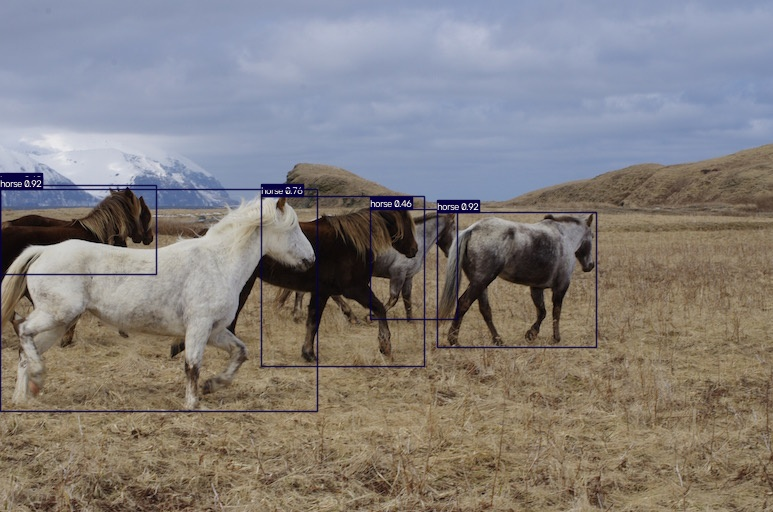

In [ ]:
%cd /content/yolov7
!python detect.py --weights yolov7-tiny.pt --source inference/images/horses.jpg --conf 0.25 --device {DEVICE} --name quicktest --exist-ok

from IPython.display import Image, display
display(Image('runs/detect/quicktest/horses.jpg', width=600))

## 6. Download 500 COCO val2017 images (not all 5,000)
We pick **500 random images** from COCO val2017. The random seed is fixed (`SEED = 0`), so you get the **same 500 images every time**. This matters, because all your experiments must use the same images to be fair.

Downloads: labels (~170 MB) + 500 images (~80 MB). Takes about 2–3 minutes.

In [ ]:
%cd /content/yolov7
import json, random, os, yaml, urllib.request
from concurrent.futures import ThreadPoolExecutor

N_IMAGES = 500   # number of images
SEED = 0         # do not change, so the same 500 images are used every time

# 1) Labels in YOLO format + official COCO annotation file
!wget -q https://github.com/ultralytics/yolov5/releases/download/v1.0/coco2017labels-segments.zip
!unzip -q -o coco2017labels-segments.zip -d ./ && rm coco2017labels-segments.zip

# 2) Pick 500 random images (same ones every time)
ann = json.load(open('coco/annotations/instances_val2017.json'))
all_files = sorted(img['file_name'] for img in ann['images'])
random.seed(SEED)
chosen = sorted(random.sample(all_files, N_IMAGES))

# 3) Download only those 500 images
img_dir = 'coco/images/val2017'
os.makedirs(img_dir, exist_ok=True)
def download(name):
    path = f'{img_dir}/{name}'
    for _ in range(3):  # try up to 3 times
        if os.path.exists(path) and os.path.getsize(path) > 0:
            return
        try:
            urllib.request.urlretrieve(f'http://images.cocodataset.org/val2017/{name}', path)
        except Exception:
            pass
with ThreadPoolExecutor(16) as pool:
    list(pool.map(download, chosen))
print("Images downloaded:", len(os.listdir(img_dir)), "of", N_IMAGES)

# 4) A data file that points to these 500 images
cfg = yaml.safe_load(open('data/coco.yaml'))
cfg['val'] = './coco/images/val2017'
yaml.safe_dump(cfg, open('data/val500_coco.yaml', 'w'))

# 5) Save the list of images to Drive (to mention in your paper)
open(f'{SAVE_DIR}/val500_image_list.txt', 'w').write('\n'.join(chosen))
print("Data file ready: data/val500_coco.yaml ✅")

/content/yolov7
Images downloaded: 500 of 500
Data file ready: data/val500_coco.yaml ✅


## 7. Baseline: measure AP on clean images
We first run **YOLOv7-tiny** (fast), then **YOLOv7** (the paper's main model).

At the end of each run, look for the line:
`Average Precision (AP) @[ IoU=0.50:0.95 | area= all | maxDets=100 ]`

That number is the **AP**. The paper reports **51.4%** for YOLOv7 (on test-dev, 20,000 images). Your number is on 500 val2017 images, so it will be close but not exactly the same. That is normal: write down the difference and explain it in your paper.

In [ ]:
%cd /content/yolov7
!python test.py --data data/val500_coco.yaml --img 640 --batch {BATCH} --conf 0.001 --iou 0.65 --device {DEVICE} --weights yolov7-tiny.pt --name baseline_tiny --exist-ok

/content/yolov7
Namespace(weights=['yolov7-tiny.pt'], data='data/val500_coco.yaml', batch_size=8, img_size=640, conf_thres=0.001, iou_thres=0.65, task='val', device='cpu', single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=True, project='runs/test', name='baseline_tiny', exist_ok=True, no_trace=False, v5_metric=False)
YOLOR 🚀 v0.1-128-ga207844 torch 2.14.1+cpu CPU

Fusing layers... 
Model Summary: 200 layers, 6219709 parameters, 6219709 gradients
 Convert model to Traced-model... 
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:976: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/py

In [10]:
%cd /content/yolov7
!python test.py --data data/val500_coco.yaml --img 640 --batch {BATCH} --conf 0.001 --iou 0.65 --device {DEVICE} --weights yolov7.pt --name baseline_yolov7 --exist-ok

               Class      Images      Labels           P           R      mAP@.5  mAP@.5:.95: 100% 63/63 [20:44<00:00, 19.75s/it]
                 all         500        3778       0.722       0.641       0.706       0.515
Speed: 2478.6/3.2/2481.8 ms inference/NMS/total per 640x640 image at batch-size 8

Evaluating pycocotools mAP... saving runs/test/baseline_yolov7/yolov7_predictions.json...
loading annotations into memory...
Done (t=1.09s)
creating index...
index created!
Loading and preparing results...
DONE (t=1.23s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=6.44s).
Accumulating evaluation results...
DONE (t=1.44s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.531
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.713
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.573
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100

## 8. Write down your results
Copy the two AP numbers from the outputs above into this table (double-click the cell to edit it).

| Model | Paper AP (test-dev) | My AP (500 val2017 images) |
|---|---|---|
| YOLOv7 | 51.4% | 53.1% |
| YOLOv7-tiny | 38.7% | 36.9% |

## 9. Save everything to Google Drive

In [1]:
!cp -r /content/yolov7/runs/test {SAVE_DIR}/baseline_results
!ls {SAVE_DIR}/baseline_results
print("Saved ✅ Now go to GitHub: File → Save a copy in GitHub, and commit this notebook.")

cp: cannot stat '/content/yolov7/runs/test': No such file or directory
ls: cannot access '{SAVE_DIR}/baseline_results': No such file or directory
Saved ✅ Now go to GitHub: File → Save a copy in GitHub, and commit this notebook.
